# 04 Quality gate, all 35

Code: `src/quality.py` (`epoch_quality`, `quality_gate`). Labels as DREAMT gives them (`label_timing="none"`).

An epoch passes when: beat count plausible, at least `q_min_kept` of its intervals kept, `template_r` at least `q_min_template_r`, motion at most `q_max_motion`. **Thresholds are first guesses (Config), not yet tuned on S042 against ECG. Motion is off (infinity) until its threshold is set.**

In [1]:
import os
%load_ext autoreload
%autoreload 2
import sys, gc
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT / "src"))
from config import Config
from recording import Recording
from preprocess import find_wristband_files
from quality import epoch_quality, quality_gate
DATA_ROOT = Path(os.environ.get("DREAMT_ROOT", PROJECT / "data" / "raw"))
FIG_DIR = PROJECT / "notebooks" / "figs"
plt.rcParams.update({"font.size": 8})
CFG = Config()
print(CFG.to_json())
SUBJECTS = list(find_wristband_files(DATA_ROOT))
LOW_IBI = ["S058", "S097", "S030", "S055"]

{"causal": false, "context_k": 4, "detect_chunk_s": 600, "detect_overlap_s": 10, "detect_pre_anchor_s": 300, "detector": "msptdfast", "epoch_s": 30, "filt_high": 8.0, "filt_low": 0.5, "filt_order": 2, "freq_win_s": 300, "fs": 64, "ibi_hi": 2.0, "ibi_lo": 0.3, "ibi_rel": 0.3, "ibi_win": 11, "label_timing": "none", "match_tol": 0.05, "q_max_motion": Infinity, "q_min_kept": 0.8, "q_min_template_r": 0.8, "seed": 20261011}


In [2]:
# LOGIC: per person, quality measures for every kept (scored) epoch, then the gate.
#   Also record which test each failed epoch fails, so the reason is visible.
#   For the example figure, keep S042's filtered BVP and beats.
# EDGE CASES: epochs with no intervals fail (NaN fails the gate).
# NOT HANDLED: thresholds not tuned; motion not used.
# CHECKED BY: tests/test_quality.py; epoch counts must match notebook 01 (28,189 in total).
Q, keep_ex = [], {}
for s in SUBJECTS:
    rec = Recording.load(s, DATA_ROOT, CFG)
    ep = rec.epochs
    k = ep.keep.to_numpy()
    q = epoch_quality(rec.bvp_filt, rec.beat_idx, rec.intervals, ep.start_sample_wrist.to_numpy()[k],
                      rec.t64[0], CFG.fs, CFG.epoch_s)
    q["motion"] = rec.motion[k]
    q["stage"] = ep.label5.to_numpy()[k]
    q["start_sample"] = ep.start_sample_wrist.to_numpy()[k]
    q["subject"] = s
    q["pass"] = quality_gate(q, q.motion, CFG)
    q["fail_plausible"] = ~q.plausible
    q["fail_kept"] = ~(q.pct_kept >= CFG.q_min_kept)
    q["fail_template"] = ~(q.template_r >= CFG.q_min_template_r)
    Q.append(q)
    if s == "S042":
        keep_ex = {"x": rec.bvp_filt, "idx": rec.beat_idx, "q": q}
    del rec; gc.collect()
    print(s, end=" ", flush=True)
Q = pd.concat(Q, ignore_index=True)
print(); print("epochs:", len(Q))
assert len(Q) == 28189

S006 

S009 

S010 

S012 

S013 

S014 

... (26 outputs left out)

S101 

S102 

S103 


epochs: 28189


In [3]:
P = Q.groupby("subject").agg(epochs=("pass", "size"), pct_pass=("pass", "mean"),
                              fail_plausible=("fail_plausible", "mean"), fail_kept=("fail_kept", "mean"),
                              fail_template=("fail_template", "mean"), median_template_r=("template_r", "median"))
P[["pct_pass", "fail_plausible", "fail_kept", "fail_template"]] *= 100
P = P.sort_values("pct_pass")
P.to_csv(PROJECT / "notebooks" / "out_quality_all35.csv")
print(P.round(1).to_string())
print(f"\nALL epochs passing: {100 * Q['pass'].mean():.1f}% ({Q['pass'].sum()} of {len(Q)})")
print(f"per person: median {P.pct_pass.median():.1f}%, range {P.pct_pass.min():.1f} to {P.pct_pass.max():.1f}")
print("\npass rate by stage (%):")
print((100 * Q.groupby("stage")["pass"].mean()).round(1).to_string())

         epochs  pct_pass  fail_plausible  fail_kept  fail_template  median_template_r
subject                                                                               
S058        794      16.6            58.3       68.1           47.6                0.8
S055        771      21.9            59.3       56.9           62.5                0.8
S097        784      29.6            29.2       42.9           62.2                0.8
S094        840      30.1            49.3       40.2           35.8                0.8
S080        726      35.1            32.5       37.3           62.3                0.7
S102        795      40.3             6.9       10.6           58.9                0.8
S101        806      49.3            16.5       15.8           48.8                0.8
S022        862      49.8            34.3       33.4           27.8                0.9
S030        843      58.4            28.8       24.3           30.5                0.9
S086        832      58.7            29.1  

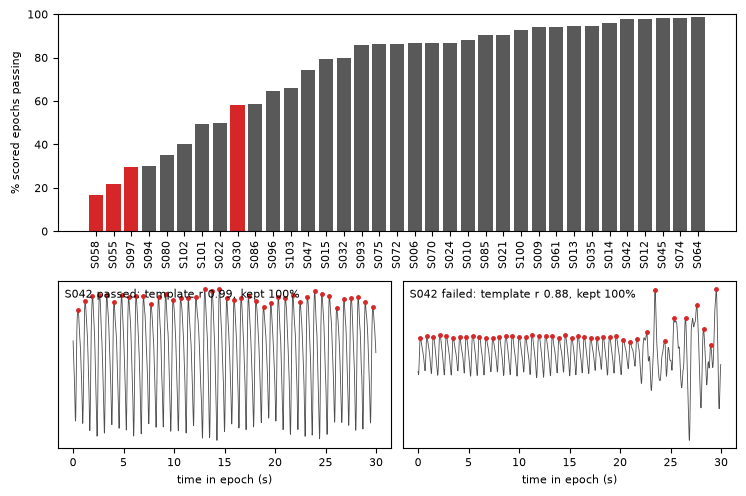

In [4]:
fig = plt.figure(figsize=(7.5, 5))
gs = fig.add_gridspec(2, 2, height_ratios=[1.3, 1])
ax = fig.add_subplot(gs[0, :])
ax.bar(P.index, P.pct_pass, color=["tab:red" if s in LOW_IBI else "0.35" for s in P.index])
ax.set_ylabel("% scored epochs passing"); ax.set_ylim(0, 100); ax.tick_params(axis="x", rotation=90)
x, idx, q = keep_ex["x"], keep_ex["idx"], keep_ex["q"]
n = CFG.fs * CFG.epoch_s
good = q[q["pass"]].sort_values("template_r").iloc[len(q[q["pass"]]) // 2]
bad = q[~q["pass"]].sort_values("template_r").iloc[len(q[~q["pass"]]) // 2]
for j, (row, lab) in enumerate([(good, "passed"), (bad, "failed")]):
    ax = fig.add_subplot(gs[1, j])
    a = int(row.start_sample); seg = x[a:a + n]; t = np.arange(n) / CFG.fs
    pk = idx[(idx >= a) & (idx < a + n)] - a
    ax.plot(t, seg, color="0.3", lw=0.6); ax.plot(pk / CFG.fs, seg[pk], "o", ms=2.5, color="tab:red")
    ax.text(0.02, 0.9, f"S042 {lab}: template r {row.template_r:.2f}, kept {100 * row.pct_kept:.0f}%",
            transform=ax.transAxes)
    ax.set_xlabel("time in epoch (s)"); ax.set_yticks([])
fig.tight_layout(); fig.savefig(FIG_DIR / "fig_quality_all35.png", dpi=150); plt.show()